# Proyek Analisis Data: [Bike Sharing Dataset]
- **Nama:** Michelle Marcelina
- **Email:** amnez.co@gmail.com
- **ID Dicoding:**

## Menentukan Pertanyaan Bisnis

- **Pertanyaan 1:** Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi selama periode 2011–2012?

- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar antara kondisi cuaca cerah dan buruk selama periode 2011–2012, serta kelompok pengguna mana yang mengalami penurunan persentase paling besar?

- **Pertanyaan 3:** Pada jam berapa rata-rata jumlah penyewaan sepeda paling tinggi dan paling rendah, serta pada jam berapa jumlah penyewaan mengalami perubahan paling besar selama periode 2011–2012?


## Import Semua Packages/Library yang Digunakan

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Data Wrangling

### Gathering Data

#### Load df ...

In [65]:
# Membaca dataset
day_df = pd.read_csv("day.csv")
hour_df = pd.read_csv("hour.csv")

# Menampilkan 5 baris pertama dari masing-masing dataset
print("Dataset Harian:")
display(day_df.head())

print("Dataset Per Jam:")
display(hour_df.head())


print("Ukuran day_df:", day_df.shape)
print("Ukuran hour_df:", hour_df.shape)


Dataset Harian:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Dataset Per Jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Ukuran day_df: (731, 16)
Ukuran hour_df: (17379, 17)


### Assessing Data

#### Identifying ... problem

In [66]:
# Memeriksa struktur dataset
day_df.info()
hour_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (tot

In [67]:
# Memeriksa tipe data
print("Tipe data dteday pada dataset day:", day_df["dteday"].dtype)
print("Tipe data dteday pada dataset hour:", hour_df["dteday"].dtype)

# Memeriksa nilai
print("Contoh nilai kolom dteday pada dataset day:")
print(day_df["dteday"].head())

print("\nContoh nilai kolom dteday pada dataset per hour:")
print(hour_df["dteday"].head())


Tipe data dteday pada dataset day: object
Tipe data dteday pada dataset hour: object
Contoh nilai kolom dteday pada dataset day:
0    2011-01-01
1    2011-01-02
2    2011-01-03
3    2011-01-04
4    2011-01-05
Name: dteday, dtype: object

Contoh nilai kolom dteday pada dataset per hour:
0    2011-01-01
1    2011-01-01
2    2011-01-01
3    2011-01-01
4    2011-01-01
Name: dteday, dtype: object


In [68]:
# Memeriksa duplicate data
print("Jumlah duplikat pada dataset day:", day_df.duplicated().sum())
print("Jumlah duplikat pada dataset hour:", hour_df.duplicated().sum())


Jumlah duplikat pada dataset day: 0
Jumlah duplikat pada dataset hour: 0


In [69]:
# Memeriksa missing values
print("Missing values day:")
print(day_df.isnull().sum())

print("\nMissing values hour:")
print(hour_df.isnull().sum())


Missing values day:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Missing values hour:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [70]:
# Memeriksa nilai negatif

#day
print("Nilai negatif pada dataset day:")
print((day_df[["casual", "registered", "cnt"]] < 0).sum())

#hour
print("\nNilai negatif pada dataset hour:")
print((hour_df[["casual", "registered", "cnt"]] < 0).sum())


Nilai negatif pada dataset day:
casual        0
registered    0
cnt           0
dtype: int64

Nilai negatif pada dataset hour:
casual        0
registered    0
cnt           0
dtype: int64


In [71]:
# Memeriksa konsistensi jumlah penyewaan

#day
print(
    "Ketidaksesuaian pada dataset day:",
    (day_df["casual"] + day_df["registered"] != day_df["cnt"]).sum()
)

#hour
print(
    "Ketidaksesuaian pada dataset hour:",
    (hour_df["casual"] + hour_df["registered"] != hour_df["cnt"]).sum()
)

Ketidaksesuaian pada dataset day: 0
Ketidaksesuaian pada dataset hour: 0


In [72]:
#Memeriksa nilai unik pada kolom kategorikal

categorical_columns = [
    "season", "yr", "mnth", "holiday",
    "weekday", "workingday", "weathersit"
]

print("Nilai unik pada dataset day:")
for col in categorical_columns:
    print(f"{col}: {sorted(day_df[col].unique())}")

print("\nNilai unik pada dataset hour:")
for col in categorical_columns:
    print(f"{col}: {sorted(hour_df[col].unique())}")

Nilai unik pada dataset day:
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int64(1), np.int64(2), np.int64(3)]

Nilai unik pada dataset hour:
season: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
yr: [np.int64(0), np.int64(1)]
mnth: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
holiday: [np.int64(0), np.int64(1)]
weekday: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
workingday: [np.int64(0), np.int64(1)]
weathersit: [np.int6

In [73]:

# Memeriksa duplikasi berdasarkan tanggal dan jam

print(
    "Duplikasi tanggal pada day_df:",
    day_df["dteday"].duplicated().sum()
)

print(
    "Duplikasi kombinasi tanggal dan jam pada hour_df:",
    hour_df.duplicated(subset=["dteday", "hr"]).sum()
)


Duplikasi tanggal pada day_df: 0
Duplikasi kombinasi tanggal dan jam pada hour_df: 0


In [74]:

# Memeriksa rentang tanggal dataset

print(
    "Rentang tanggal day_df:",
    day_df["dteday"].min(),
    "sampai",
    day_df["dteday"].max()
)

print(
    "Rentang tanggal hour_df:",
    hour_df["dteday"].min(),
    "sampai",
    hour_df["dteday"].max()
)


Rentang tanggal day_df: 2011-01-01 sampai 2012-12-31
Rentang tanggal hour_df: 2011-01-01 sampai 2012-12-31


In [75]:

# Memeriksa validitas nilai jam

print(
    "Jumlah nilai jam tidak valid:",
    (~hour_df["hr"].between(0, 23)).sum()
)


Jumlah nilai jam tidak valid: 0


**Steps to Take:**

- Mengubah tipe data kolom dteday pada dataset day_df dan hour_df dari object menjadi datetime.
- Memeriksa kembali tipe data setelah proses perubahan dilakukan.
- Mempertahankan data yang sudah memenuhi kriteria pemeriksaan karena tidak ditemukan missing values, data duplikat, nilai negatif pada jumlah penyewaan, maupun ketidaksesuaian antara casual, registered, dan cnt.
- Melanjutkan ke tahap Exploratory Data Analysis (EDA) setelah proses pembersihan selesai.

**Insight:**
- Dataset day_df memiliki 731 baris, sedangkan hour_df memiliki 17.379 baris.
- Kedua dataset tidak memiliki missing values maupun duplikasi baris berdasarkan hasil pemeriksaan.
- Tidak ditemukan nilai negatif pada kolom casual, registered, dan cnt.
- Jumlah casual dan registered sesuai dengan nilai cnt pada kedua dataset.
- Kolom dteday masih bertipe object, sehingga perlu diubah menjadi datetime agar dapat digunakan sebagai tipe data tanggal.

### Cleaning Data

#### Fixing ... problem

In [76]:
# Mengubah tipe data dteday menjadi datetime
day_df["dteday"] = pd.to_datetime(day_df["dteday"])
hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])

# Memeriksa hasil cleaning
print("Tipe data dteday pada day_df:", day_df["dteday"].dtype)
print("Tipe data dteday pada hour_df:", hour_df["dteday"].dtype)

print("\nMissing values pada dteday day_df:", day_df["dteday"].isnull().sum())
print("Missing values pada dteday hour_df:", hour_df["dteday"].isnull().sum())


Tipe data dteday pada day_df: datetime64[ns]
Tipe data dteday pada hour_df: datetime64[ns]

Missing values pada dteday day_df: 0
Missing values pada dteday hour_df: 0


**Insight:**
- dteday pada dataset day_df dan hour_df berhasil diubah dari tipe data object menjadi datetime. Perubahan ini dilakukan agar kolom tanggal memiliki tipe data yang sesuai dan dapat digunakan dalam analisis berbasis waktu. Setelah proses perubahan, jumlah missing values pada kolom dteday juga diperiksa kembali untuk memastikan tidak ada nilai tanggal yang kosong.

## Exploratory Data Analysis (EDA)

### Explore ...

In [31]:
# Melihat statistik variabel utama
kolom_utama = ["casual", "registered", "cnt"]

display(day_df[kolom_utama].describe())


,casual,registered,cnt
count,731.000000,731.000000,731.000000
mean,848.176471,3656.172367,4504.348837
std,686.622488,1560.256377,1937.211452
min,2.000000,20.000000,22.000000
25%,315.500000,2497.000000,3152.000000
50%,713.000000,3662.000000,4548.000000
75%,1096.000000,4776.500000,5956.000000
max,3410.000000,6946.000000,8714.000000


Rata-rata penyewaan sepeda setiap hari adalah 4.504,35. Pengguna terdaftar lebih banyak menyewa sepeda dibandingkan pengguna kasual. Jumlah penyewaan juga berbeda-beda setiap harinya, dengan jumlah tertinggi mencapai 8.714 penyewaan.

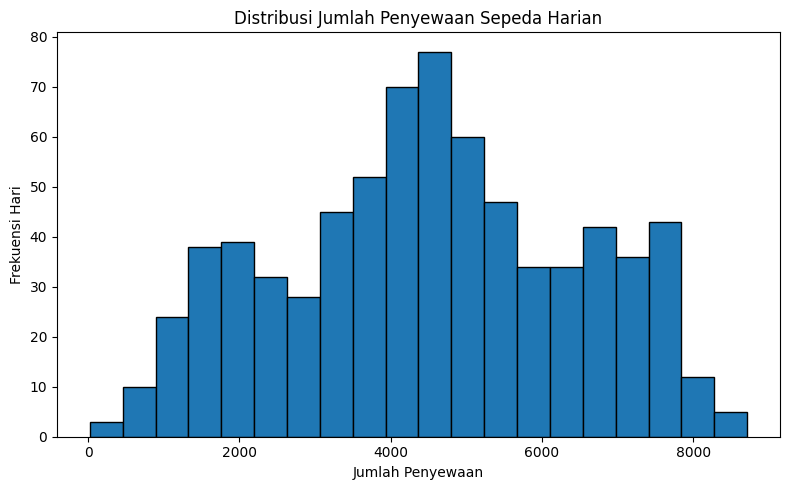

In [32]:
#Melihat distribusi jumlah penyewaan harian
plt.figure(figsize=(8, 5))
plt.hist(day_df["cnt"], bins=20, edgecolor="black")

plt.title("Distribusi Jumlah Penyewaan Sepeda Harian")
plt.xlabel("Jumlah Penyewaan")
plt.ylabel("Frekuensi Hari")
plt.tight_layout()
plt.show()


Histogram menunjukkan bahwa jumlah penyewaan sepeda harian memiliki sebaran yang cukup beragam.

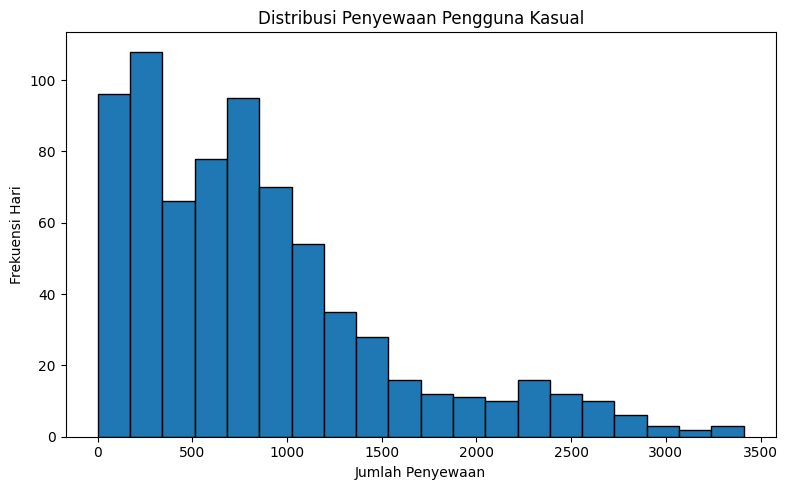

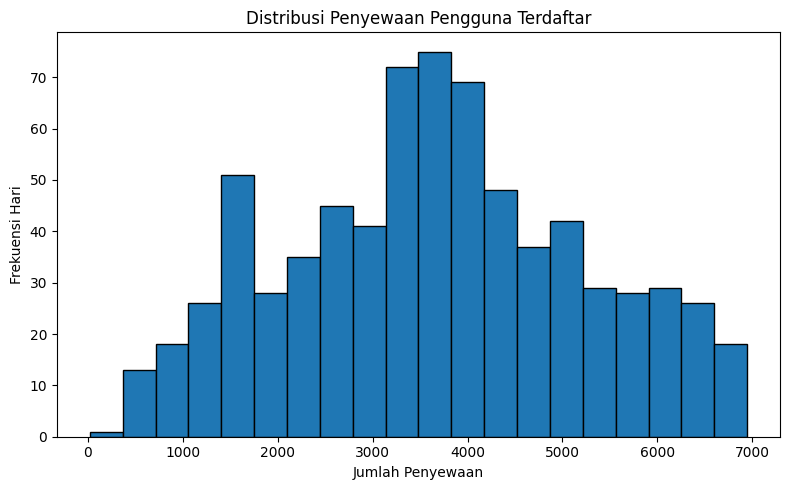

In [33]:
cc


Histogram menunjukkan bahwa jumlah penyewaan pengguna kasual dan pengguna terdaftar memiliki sebaran yang berbeda. Pengguna terdaftar memiliki jumlah penyewaan harian yang cenderung lebih tinggi dibandingkan pengguna kasual. Pada kedua kelompok, jumlah penyewaan juga bervariasi dari hari ke hari.

In [40]:
#statistik penyewaan berdasarkan musim
season_summary = day_df.groupby("season")["cnt"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

display(season_summary)


,count,mean,median,std,min,max
season,,,,,,
1,181,2604.13,2209.0,1399.94,431,7836
2,184,4992.33,4941.5,1695.98,795,8362
3,188,5644.30,5353.5,1459.80,1115,8714
4,178,4728.16,4634.5,1699.62,22,8555


Rata-rata penyewaan sepeda tertinggi pada musim Fall yaitu 5.644,30 penyewaan per hari dan rata-rata penyewaan terendah ada pada musim Spring

In [37]:
# Ringkasan penyewaan berdasarkan kondisi cuaca
weather_summary = day_df.groupby("weathersit")[
    ["casual", "registered", "cnt"]
].agg(["mean", "median"])

display(weather_summary.round(2))


casual        registered              cnt        
              mean median       mean  median     mean  median
weathersit                                                   
1           964.03  829.0    3912.76  3875.0  4876.79  4844.0
2           687.35  534.0    3348.51  3352.0  4035.86  4040.0
3           185.48  126.0    1617.81  1672.0  1803.29  1817.0

rata-rata penyewaan sepeda cenderung lebih tinggi penurunan penyewaan terlihat pada pengguna kasual maupun pengguna terdaftar. Hal ini menunjukkan bahwa kondisi cuaca berkaitan dengan perubahan jumlah penyewaan sepeda.

In [41]:
# Memeriksa kode musim pada dataset
display(day_df["season"].value_counts().sort_index())


,count
season,
1,181
2,184
3,188
4,178


Hasil pemeriksaan menunjukkan jumlah data yang tercatat pada setiap kode musim. Informasi ini membantu memastikan bahwa data dari keempat musim tersedia untuk dibandingkan dalam analisis penyewaan sepeda.

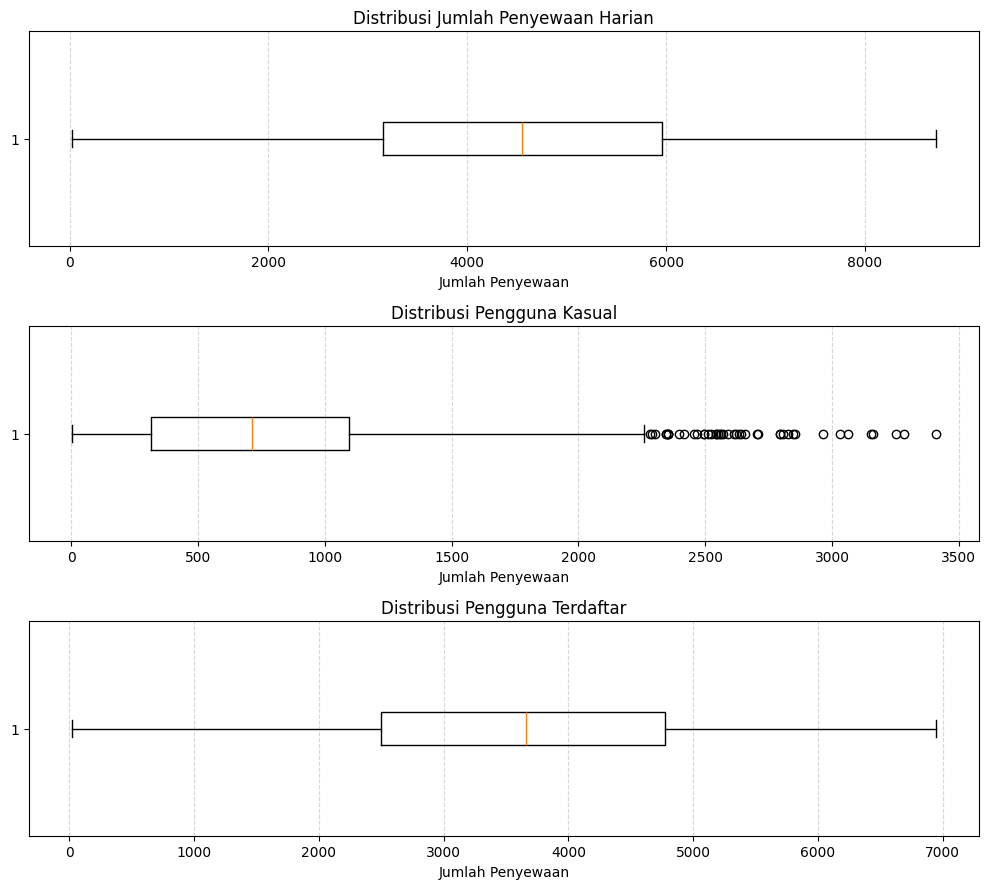

In [46]:
# Boxplot untuk melihat distribusi dan potensi outlier
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

kolom_boxplot = ["cnt", "casual", "registered"]
judul_boxplot = [
    "Distribusi Jumlah Penyewaan Harian",
    "Distribusi Pengguna Kasual",
    "Distribusi Pengguna Terdaftar"
]

for ax, kolom, judul in zip(axes, kolom_boxplot, judul_boxplot):
    ax.boxplot(day_df[kolom], vert=False)
    ax.set_title(judul)
    ax.set_xlabel("Jumlah Penyewaan")
    ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


menunjukkan bahwa jumlah penyewaan oleh pengguna terdaftar cenderung lebih tinggi dibandingkan pengguna kasual. Keberadaan outlier pada pengguna kasual juga menunjukkan adanya hari-hari dengan pola penyewaan yang berbeda dari kondisi umumnya.

,temp,atemp,hum,windspeed,casual,registered,cnt
temp,1.00,0.99,0.13,-0.16,0.54,0.54,0.63
atemp,0.99,1.00,0.14,-0.18,0.54,0.54,0.63
hum,0.13,0.14,1.00,-0.25,-0.08,-0.09,-0.10
windspeed,-0.16,-0.18,-0.25,1.00,-0.17,-0.22,-0.23
casual,0.54,0.54,-0.08,-0.17,1.00,0.40,0.67
registered,0.54,0.54,-0.09,-0.22,0.40,1.00,0.95
cnt,0.63,0.63,-0.10,-0.23,0.67,0.95,1.00


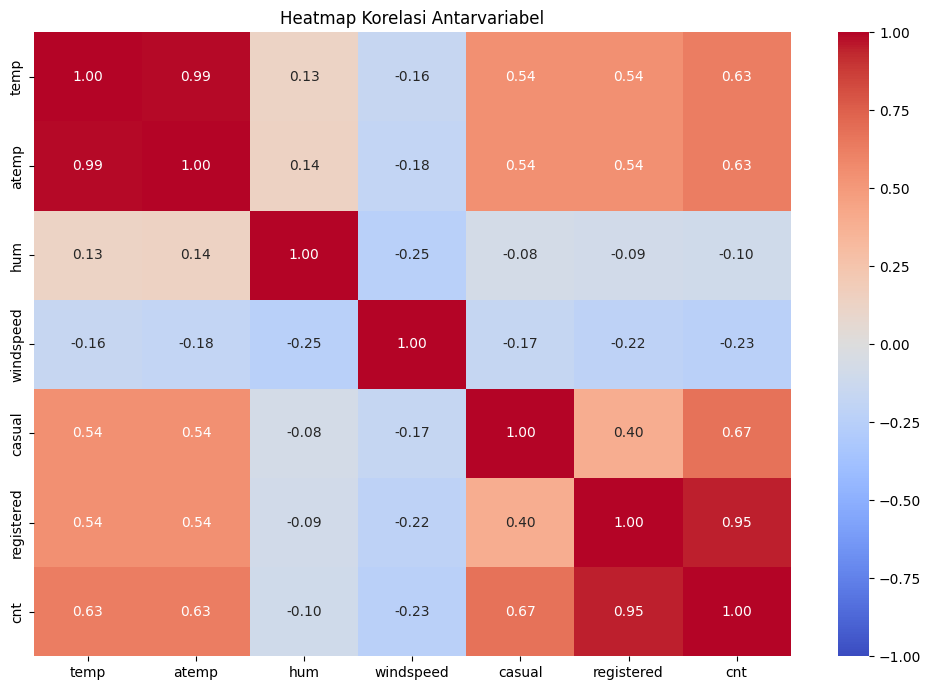

In [47]:
# Melihat korelasi antarvariabel numerik
kolom_korelasi = [
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

correlation_matrix = day_df[kolom_korelasi].corr()

display(correlation_matrix.round(2))

# Membuat heatmap korelasi
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Heatmap Korelasi Antarvariabel")
plt.tight_layout()
plt.show()


Berdasarkan hasil analisis korelasi, dapat disimpulkan beberapa hal berikut:

- Jumlah pengguna terdaftar (registered) memiliki hubungan paling kuat dengan total penyewaan sepeda (cnt), dengan nilai korelasi sebesar 0,95.
- Jumlah pengguna kasual (casual) juga memiliki hubungan positif dengan total penyewaan sepeda, dengan nilai korelasi sebesar 0,67.
- Suhu (temp) dan suhu yang dirasakan (atemp) sama-sama memiliki korelasi sebesar 0,63 dengan total penyewaan sepeda. Hal ini menunjukkan bahwa suhu yang lebih tinggi cenderung diikuti oleh peningkatan jumlah penyewaan.
- Kelembapan (hum) dan kecepatan angin (windspeed) memiliki hubungan negatif dengan total penyewaan sepeda, masing-masing sebesar -0,10 dan -0,23. Namun, hubungan keduanya tergolong lemah.
- Suhu (temp) dan suhu yang dirasakan (atemp) memiliki korelasi sangat tinggi, yaitu 0,99. Artinya, perubahan pada kedua variabel tersebut cenderung sejalan dan informasinya hampir serupa.

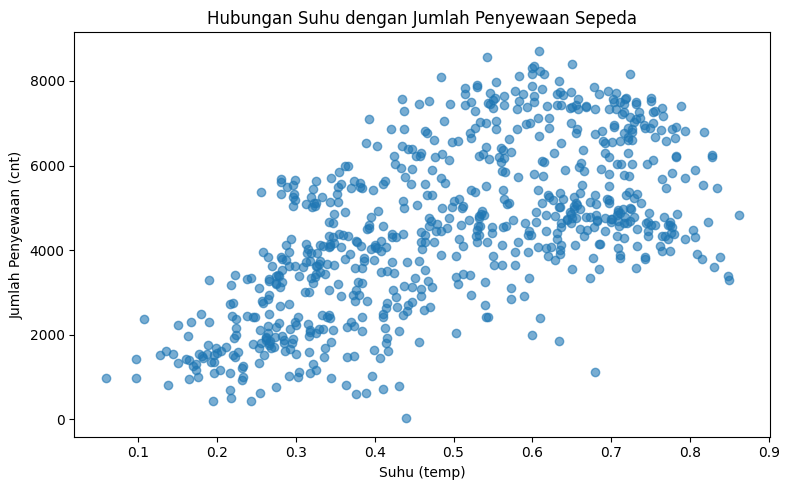

In [48]:
# Melihat hubungan suhu dengan jumlah penyewaan
plt.figure(figsize=(8, 5))

plt.scatter(
    day_df["temp"],
    day_df["cnt"],
    alpha=0.6
)

plt.title("Hubungan Suhu dengan Jumlah Penyewaan Sepeda")
plt.xlabel("Suhu (temp)")
plt.ylabel("Jumlah Penyewaan (cnt)")
plt.tight_layout()
plt.show()


Hasil menunjukan hubungan positif antara suhu dan jumlah penyewaan sepeda.
Pada suhu yang relatif rendah, jumlah penyewaan cenderung lebih sedikit. Sementara itu, ketika suhu meningkat, jumlah penyewaan secara umum juga cenderung meningkat.

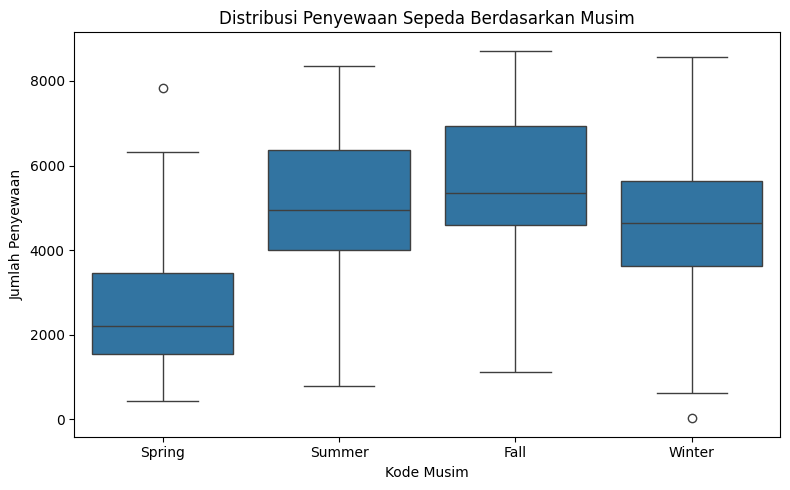

In [60]:
# Membandingkan distribusi penyewaan berdasarkan musim
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=day_df,
    x="season",
    y="cnt"
)

plt.title("Distribusi Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Kode Musim")
plt.ylabel("Jumlah Penyewaan")
plt.xticks(
    ticks=[0, 1, 2, 3],
    labels=["Spring", "Summer", "Fall", "Winter"]
)
plt.tight_layout()
plt.show()


jumlah penyewaan sepeda cenderung lebih tinggi pada summer dan fall. fall memiliki rata-rata penyewaan tertinggi, sedangkan spring terendah

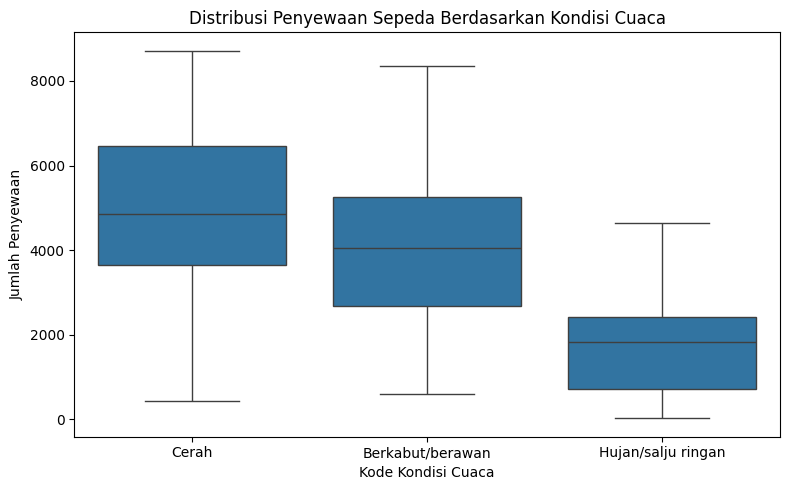

In [64]:
# Membandingkan distribusi penyewaan berdasarkan kondisi cuaca
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=day_df,
    x="weathersit",
    y="cnt"
)

plt.title("Distribusi Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kode Kondisi Cuaca")
plt.ylabel("Jumlah Penyewaan")
plt.xticks(
    ticks=[0, 1, 2],
    labels=["Cerah", "Berkabut/berawan", "Hujan/salju ringan"]
)
plt.tight_layout()
plt.show()


 jumlah penyewaan sepeda cenderung lebih tinggi saat cuaca cerah dibandingkan saat berkabut atau hujan dan penyewaan sepeda terendah saat cuaca hujan/salju ringan

In [42]:
# Menghitung rata-rata penyewaan sepeda berdasarkan musim
season_rentals = day_df.groupby("season")["cnt"].mean().reset_index()

# Mengurutkan berdasarkan rata-rata penyewaan tertinggi
season_rentals = season_rentals.sort_values(
    by="cnt", ascending=False
)

display(season_rentals)


,season,cnt
2,3,5644.303191
1,2,4992.331522
3,4,4728.162921
0,1,2604.132597


Hasil menununjukkan rata-rata penyewaan sepeda paling tinggi terjadi pada musim Fall, yaitu sekitar 5.644 sepeda per hari. Sebaliknya, musim Spring memiliki rata-rata penyewaan paling rendah, yaitu sekitar 2.604 sepeda per hari. Hal ini menunjukkan bahwa musim Fall menjadi musim dengan jumlah penyewaan sepeda harian tertinggi selama periode 2011–2012.

In [63]:
# Menghitung rata-rata penyewaan saat cuaca cerah
cerah = day_df[day_df["weathersit"] == 1][
    ["casual", "registered"]
].mean()

# Menghitung rata-rata penyewaan saat cuaca buruk
cuaca_buruk = day_df[day_df["weathersit"].isin([3, 4])][
    ["casual", "registered"]
].mean()

# Membandingkan rata-rata penyewaan
weather_comparison = pd.DataFrame({
    "Cerah": cerah,
    "Cuaca Buruk": cuaca_buruk
})

display(weather_comparison)

# Menghitung persentase penurunan
penurunan = (
    (cerah - cuaca_buruk) / cerah
) * 100

print("\nPersentase penurunan penyewaan:")
print(f"Pengguna kasual: {penurunan['casual']:.2f}%")
print(f"Pengguna terdaftar: {penurunan['registered']:.2f}%")



,Cerah,Cuaca Buruk
casual,964.030238,185.476190
registered,3912.755940,1617.809524



Persentase penurunan penyewaan:
Pengguna kasual: 80.76%
Pengguna terdaftar: 58.65%


Hasil menunjukkan rata-rata penyewaan pengguna kasual turun dari 964,03 saat cuaca cerah menjadi 185,48 saat cuaca buruk. Sementara itu, pengguna terdaftar turun dari 3.912,76 menjadi 1.617,81 penyewaan. Persentase penurunan pengguna kasual sebesar 80,76%, lebih besar dibandingkan pengguna terdaftar yang sebesar 58,65%. Dengan demikian, pengguna kasual mengalami penurunan persentase paling besar saat cuaca buruk.

In [78]:

# Menghitung rata-rata penyewaan sepeda berdasarkan jam
hourly_rentals = hour_df.groupby("hr")["cnt"].mean().reset_index()

# Menampilkan hasil rata-rata penyewaan setiap jam
display(hourly_rentals)

# Mencari jam dengan rata-rata penyewaan tertinggi dan terendah
jam_tertinggi = hourly_rentals.loc[hourly_rentals["cnt"].idxmax()]
jam_terendah = hourly_rentals.loc[hourly_rentals["cnt"].idxmin()]

print("Rata-rata penyewaan tertinggi:")
print(
    f"Jam {int(jam_tertinggi['hr']):02d}:00 = "
    f"{jam_tertinggi['cnt']:.2f} penyewaan"
)

print("\nRata-rata penyewaan terendah:")
print(
    f"Jam {int(jam_terendah['hr']):02d}:00 = "
    f"{jam_terendah['cnt']:.2f} penyewaan"
)

# Menghitung perubahan rata-rata antara jam yang berurutan
hourly_rentals["perubahan"] = hourly_rentals["cnt"].diff()

# Mencari kenaikan rata-rata terbesar
kenaikan_terbesar = hourly_rentals.loc[
    hourly_rentals["perubahan"].idxmax()
]

# Mencari penurunan rata-rata terbesar
penurunan_terbesar = hourly_rentals.loc[
    hourly_rentals["perubahan"].idxmin()
]

print("\nKenaikan rata-rata terbesar:")
print(
    f"Dari jam {int(kenaikan_terbesar['hr']) - 1:02d}:00 "
    f"ke jam {int(kenaikan_terbesar['hr']):02d}:00, "
    f"naik {kenaikan_terbesar['perubahan']:.2f} penyewaan"
)

print("\nPenurunan rata-rata terbesar:")
print(
    f"Dari jam {int(penurunan_terbesar['hr']) - 1:02d}:00 "
    f"ke jam {int(penurunan_terbesar['hr']):02d}:00, "
    f"turun {abs(penurunan_terbesar['perubahan']):.2f} penyewaan"
)


,hr,cnt
0,0,53.898072
1,1,33.375691
2,2,22.869930
3,3,11.727403
4,4,6.352941
5,5,19.889819
6,6,76.044138
7,7,212.064649
8,8,359.011004
9,9,219.309491


Rata-rata penyewaan tertinggi:
Jam 17:00 = 461.45 penyewaan

Rata-rata penyewaan terendah:
Jam 04:00 = 6.35 penyewaan

Kenaikan rata-rata terbesar:
Dari jam 16:00 ke jam 17:00, naik 149.47 penyewaan

Penurunan rata-rata terbesar:
Dari jam 08:00 ke jam 09:00, turun 139.70 penyewaan


Rata-rata penyewaan sepeda paling tinggi terjadi pada pukul 17.00, sedangkan yang paling rendah terjadi pada pukul 04.00. Kenaikan terbesar terjadi dari pukul 16.00 ke 17.00, sementara penurunan terbesar terjadi dari pukul 08.00 ke 09.00. Hasil ini menunjukkan bahwa jumlah penyewaan berubah sepanjang hari dan cenderung meningkat pada sore hari.

## Visualization & Explanatory Analysis

### Pertanyaan 1:Pada musim apa rata-rata jumlah penyewaan sepeda harian paling tinggi selama periode 2011–2012?



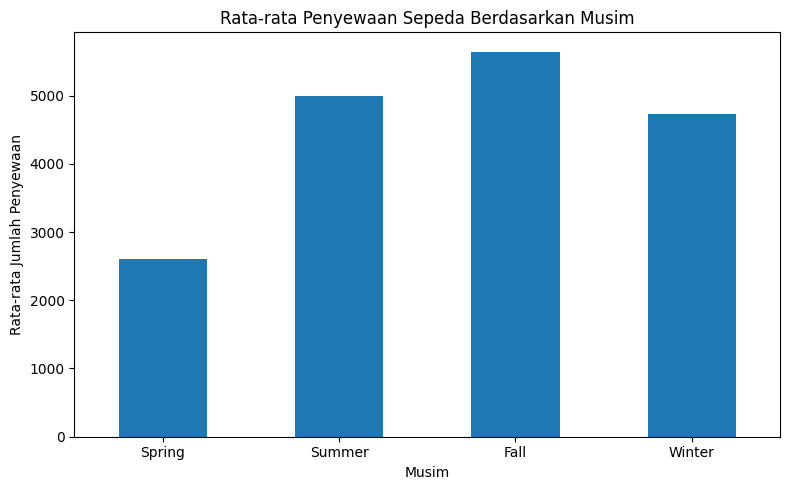

In [61]:
# Mengurutkan musim sesuai kode agar grafik mudah dibaca
season_plot = day_df.groupby("season")["cnt"].mean()

season_names = {
    1: "Spring",
    2: "Summer",
    3: "Fall",
    4: "Winter"
}

season_plot.index = season_plot.index.map(season_names)

season_plot = season_plot.reindex(
    ["Spring", "Summer", "Fall", "Winter"]
)

# Membuat bar chart
plt.figure(figsize=(8, 5))
season_plot.plot(kind="bar")

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Musim")
plt.xlabel("Musim")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Berdasarkan grafik, musim Fall memiliki rata-rata penyewaan sepeda harian tertinggi, yaitu 5.644,30 penyewaan. Sementara itu, musim Spring memiliki rata-rata terendah, yaitu sekitar 2.604,13 penyewaan per hari. Hasil ini menunjukkan bahwa jumlah penyewaan sepeda berbeda pada setiap musim selama periode 2011–2012.

### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda oleh pengguna kasual dan pengguna terdaftar antara kondisi cuaca cerah dan buruk selama periode 2011–2012, serta kelompok pengguna mana yang mengalami penurunan persentase paling besar?



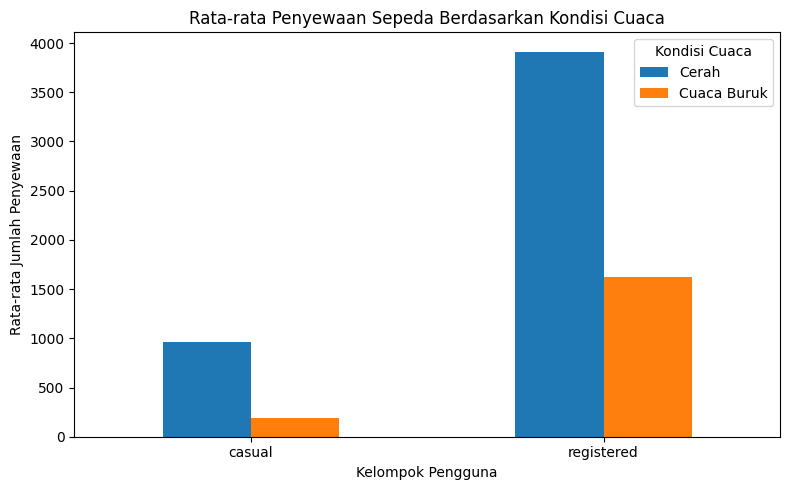

In [ ]:
# Membuat grafik perbandingan rata-rata penyewaan
weather_comparison.plot(kind="bar", figsize=(8, 5))

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca")
plt.xlabel("Kelompok Pengguna")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(rotation=0)
plt.legend(title="Kondisi Cuaca")
plt.tight_layout()
plt.show()

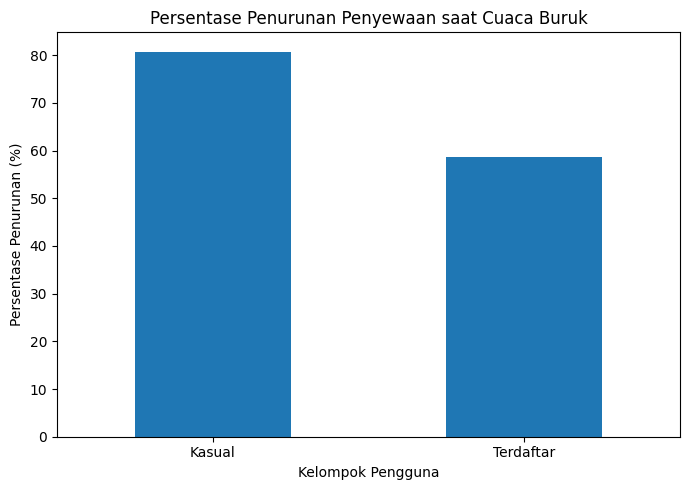

In [ ]:
# Menyiapkan data persentase penurunan
decrease_data = pd.Series({
    "Kasual": penurunan["casual"],
    "Terdaftar": penurunan["registered"]
})

# Membuat grafik persentase penurunan
decrease_data.plot(kind="bar", figsize=(7, 5))

plt.title("Persentase Penurunan Penyewaan saat Cuaca Buruk")
plt.xlabel("Kelompok Pengguna")
plt.ylabel("Persentase Penurunan (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Berdasarkan grafik, rata-rata penyewaan pengguna kasual turun dari 964,03 saat cuaca cerah menjadi 185,48 saat cuaca buruk. Sementara itu, pengguna terdaftar turun dari 3.912,76 menjadi 1.617,81 penyewaan. Persentase penurunan pengguna kasual sebesar 80,76%, sedangkan pengguna terdaftar sebesar 58,65%. Dengan demikian, pengguna kasual mengalami penurunan persentase yang lebih besar saat cuaca buruk.


### Pertanyaan 3: Pada jam berapa rata-rata jumlah penyewaan sepeda paling tinggi dan paling rendah, serta pada jam berapa jumlah penyewaan mengalami perubahan paling besar selama periode 2011–2012?

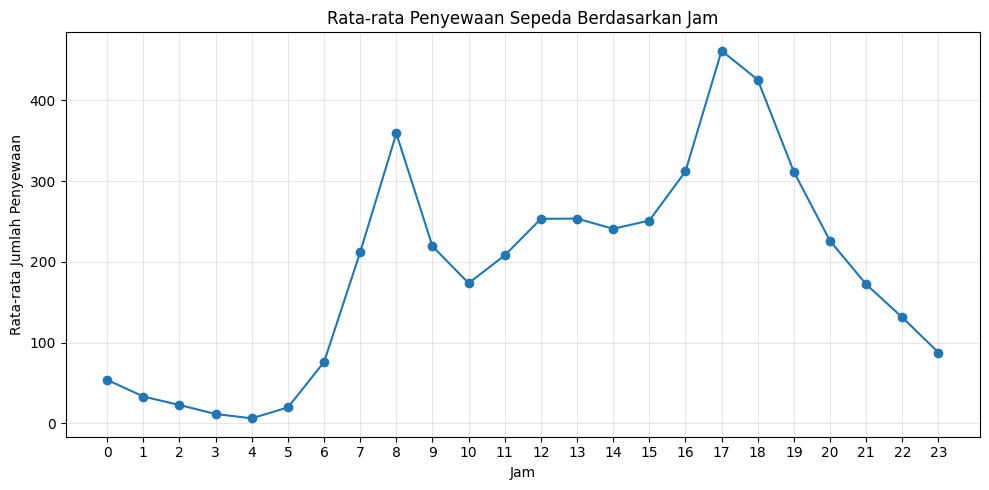

Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, sebanyak 461.45 penyewaan.
Rata-rata penyewaan terendah terjadi pada pukul 04.00, sebanyak 6.35 penyewaan.
Kenaikan rata-rata penyewaan terbesar terjadi dari pukul 16.00 ke 17.00, sebesar 149.47 penyewaan.
Penurunan rata-rata penyewaan terbesar terjadi dari pukul 08.00 ke 09.00, sebesar 139.70 penyewaan.


In [55]:
# Menghitung rata-rata penyewaan sepeda berdasarkan jam
hourly_plot = hour_df.groupby("hr")["cnt"].mean()

# Membuat grafik rata-rata penyewaan berdasarkan jam
plt.figure(figsize=(10, 5))
plt.plot(hourly_plot.index, hourly_plot.values, marker="o")

plt.title("Rata-rata Penyewaan Sepeda Berdasarkan Jam")
plt.xlabel("Jam")
plt.ylabel("Rata-rata Jumlah Penyewaan")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Mencari jam dengan rata-rata penyewaan tertinggi dan terendah
jam_tertinggi = hourly_plot.idxmax()
jam_terendah = hourly_plot.idxmin()

print(f"Rata-rata penyewaan tertinggi terjadi pada pukul {jam_tertinggi:02d}.00, "
      f"sebanyak {hourly_plot.loc[jam_tertinggi]:.2f} penyewaan.")

print(f"Rata-rata penyewaan terendah terjadi pada pukul {jam_terendah:02d}.00, "
      f"sebanyak {hourly_plot.loc[jam_terendah]:.2f} penyewaan.")

# Menghitung perubahan rata-rata penyewaan dari satu jam ke jam berikutnya
hourly_plot_change = hourly_plot.diff()

# Mencari kenaikan dan penurunan terbesar
jam_kenaikan = hourly_plot_change.idxmax()
jam_penurunan = hourly_plot_change.idxmin()

print(f"Kenaikan rata-rata penyewaan terbesar terjadi dari pukul "
      f"{jam_kenaikan - 1:02d}.00 ke {jam_kenaikan:02d}.00, "
      f"sebesar {hourly_plot_change.loc[jam_kenaikan]:.2f} penyewaan.")

print(f"Penurunan rata-rata penyewaan terbesar terjadi dari pukul "
      f"{jam_penurunan - 1:02d}.00 ke {jam_penurunan:02d}.00, "
      f"sebesar {abs(hourly_plot_change.loc[jam_penurunan]):.2f} penyewaan.")

## Conclusion & Recommendation

Conclusion pertanyaan 1: Rata-rata penyewaan sepeda tertinggi terjadi pada musim Fall, yaitu sekitar 5.644 penyewaan per hari. Sementara itu, musim Spring memiliki rata-rata terendah, yaitu sekitar 2.604 penyewaan per hari.

Conclusion pertanyaan 2: Jumlah penyewaan menurun saat cuaca buruk, baik pada pengguna kasual maupun pengguna terdaftar. Pengguna kasual mengalami penurunan sebesar 80,76%, sedangkan pengguna terdaftar mengalami penurunan sebesar 58,65%. Dengan demikian, pengguna kasual mengalami penurunan persentase yang lebih besar.

Conclusion pertanyaan 3: Rata-rata penyewaan tertinggi terjadi pada pukul 17.00, yaitu 461,45 penyewaan, sedangkan yang terendah terjadi pada pukul 04.00, yaitu 6,35 penyewaan. Kenaikan terbesar terjadi dari pukul 16.00 ke 17.00 sebesar 149,47 penyewaan, sedangkan penurunan terbesar terjadi dari pukul 08.00 ke 09.00 sebesar 139,70 penyewaan.

**Rekomendasi Action Item:**
- Menambah kesiapan dan ketersediaan sepeda menjelang sore, terutama sekitar pukul 16.00–17.00, untuk memenuhi tingginya permintaan.

- Menyesuaikan ketersediaan sepeda dengan pola permintaan setiap musim, terutama pada musim Fall yang memiliki rata-rata penyewaan tertinggi.

- Mempertimbangkan promosi bagi pengguna kasual saat cuaca kurang mendukung untuk mendorong penyewaan.